# Analyse statistique des variables `Age` et `MentHlth`

**Jeu de données :** `diabetes_012_health_indicators_BRFSS2015.csv`  
**Objectif :** réaliser une analyse descriptive, traiter les valeurs manquantes et atypiques, normaliser les variables et visualiser leurs distributions.

> **Avant de commencer :** placez le fichier CSV dans le même dossier que ce notebook. Exécutez ensuite les cellules dans l'ordre avec **Kernel → Restart & Run All**.

## Sommaire
1. Importation des bibliothèques et chargement des données
2. Préparation de la variable `Age`
3. Mesures statistiques descriptives
4. Interprétation et distributions de fréquences
5. Gestion des valeurs manquantes
6. Détection et traitement des valeurs atypiques
7. Normalisation
8. Visualisations
9. Analyse croisée entre l'âge et la santé mentale
10. Conclusion

## 1. Importation des bibliothèques et chargement des données

Nous utilisons Pandas pour manipuler les données, NumPy pour les calculs et Matplotlib/Seaborn pour les graphiques.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Le fichier CSV doit se trouver dans le même dossier que ce notebook.
CSV_PATH = Path("diabetes_012_health_indicators_BRFSS2015.csv")

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {CSV_PATH.resolve()}\n"
        "Placez le fichier CSV dans le même dossier que le notebook."
    )

df = pd.read_csv(CSV_PATH)

print("Dimensions du dataset :", df.shape)
display(df.head())

Dimensions du dataset : (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


### 1.1. Sélection des variables étudiées

- **`Age`** : tranche d'âge codée par un entier de 1 à 13. Ce sont des catégories ordonnées et non des âges exacts.
- **`MentHlth`** : nombre de jours, sur les 30 derniers jours, pendant lesquels la personne a déclaré une mauvaise santé mentale. Les valeurs vont de 0 à 30.

Nous limitons l'analyse aux deux variables demandées.

In [2]:
variables = ["Age", "MentHlth"]

# Vérifier les types, les dimensions et quelques observations
print(df[variables].info())
display(df[variables].head())
print("\nValeurs distinctes de Age :", sorted(df["Age"].dropna().unique()))
print("Valeurs distinctes de MentHlth :", sorted(df["MentHlth"].dropna().unique()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Age       253680 non-null  float64
 1   MentHlth  253680 non-null  float64
dtypes: float64(2)
memory usage: 3.9 MB
None


,Age,MentHlth
0,9.0,18.0
1,7.0,0.0
2,9.0,30.0
3,11.0,0.0
4,11.0,3.0



Valeurs distinctes de Age : [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0)]
Valeurs distinctes de MentHlth : [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0)]


## 2. Préparation de la variable `Age`

On crée une nouvelle colonne contenant les libellés des tranches d'âge. On conserve la colonne `Age` originale pour effectuer les calculs numériques et éviter de perdre les codes d'origine.

In [3]:
age_mapping = {
    1: "18-24 ans",
    2: "25-29 ans",
    3: "30-34 ans",
    4: "35-39 ans",
    5: "40-44 ans",
    6: "45-49 ans",
    7: "50-54 ans",
    8: "55-59 ans",
    9: "60-64 ans",
    10: "65-69 ans",
    11: "70-74 ans",
    12: "75-79 ans",
    13: "80 ans ou plus"
}

age_order = list(age_mapping.values())
df["Age_categorie"] = pd.Categorical(
    df["Age"].map(age_mapping),
    categories=age_order,
    ordered=True
)

display(df[["Age", "Age_categorie"]].head(10))

# Vérifier que tous les codes ont bien reçu une catégorie
print("Catégories non renseignées après le mapping :", df["Age_categorie"].isna().sum())

,Age,Age_categorie
0,9.0,60-64 ans
1,7.0,50-54 ans
2,9.0,60-64 ans
3,11.0,70-74 ans
4,11.0,70-74 ans
5,10.0,65-69 ans
6,9.0,60-64 ans
7,11.0,70-74 ans
8,9.0,60-64 ans
9,8.0,55-59 ans


Catégories non renseignées après le mapping : 0


## 3. Calcul des mesures statistiques descriptives

Pour chaque variable, nous calculons l'effectif, la moyenne, la médiane, le mode, le minimum, le maximum, les quartiles, la variance, l'écart-type, le coefficient d'asymétrie (*skewness*) et l'aplatissement (*kurtosis*).

**Précaution d'interprétation :** les codes de `Age` représentent des catégories ordinales. La moyenne, la variance, le skewness et le kurtosis de ces codes sont donc des résumés numériques approximatifs de l'ordre des catégories, et non des mesures calculées sur des âges réels en années.

In [4]:
def calculer_statistiques(serie):
    modes = serie.mode().tolist()
    return pd.Series({
        "Effectif": serie.count(),
        "Moyenne": serie.mean(),
        "Médiane": serie.median(),
        "Mode(s)": ", ".join(map(str, modes)),
        "Minimum": serie.min(),
        "Q1 (25 %)": serie.quantile(0.25),
        "Q3 (75 %)": serie.quantile(0.75),
        "Maximum": serie.max(),
        "Variance": serie.var(),
        "Écart-type": serie.std(),
        "Skewness": serie.skew(),
        "Kurtosis": serie.kurt()
    })

statistiques = pd.DataFrame({
    variable: calculer_statistiques(df[variable])
    for variable in variables
}).T

display(statistiques.round(3))

,Effectif,Moyenne,Médiane,Mode(s),Minimum,Q1 (25 %),Q3 (75 %),Maximum,Variance,Écart-type,Skewness,Kurtosis
Age,253680,8.032119,8.0,9.0,1.0,6.0,10.0,13.0,9.328262,3.05422,-0.359903,-0.581223
MentHlth,253680,3.184772,0.0,0.0,0.0,0.0,2.0,30.0,54.950296,7.412847,2.721148,6.441684


### 3.1. Interprétation des mesures statistiques

**Variable `Age`**

- La moyenne des codes est d'environ **8,03**, proche du code 8 (55-59 ans). Elle ne correspond pas à un âge moyen en années.
- La médiane est **8** : la catégorie centrale dans l'ordre des codes est 55-59 ans.
- Le mode est **9**, soit **60-64 ans** : c'est la tranche la plus fréquente.
- Le skewness est négatif (environ **-0,36**) : la distribution des codes présente une légère asymétrie à gauche.

**Variable `MentHlth`**

- La moyenne est d'environ **3,18 jours**, alors que la médiane et le mode sont égaux à **0 jour**.
- L'écart entre la moyenne et la médiane montre que quelques valeurs élevées tirent la moyenne vers le haut.
- Le skewness est fortement positif (environ **2,72**) : la distribution est très asymétrique à droite.
- Le kurtosis est élevé (environ **6,44**) : la distribution présente une concentration importante et des valeurs éloignées du centre.

La distribution de `MentHlth` n'est donc pas symétrique : la plupart des observations sont proches de zéro, mais certaines personnes déclarent un nombre élevé de jours.

## 4. Distribution des fréquences

La fréquence relative est calculée en divisant l'effectif d'une modalité par le nombre total d'observations, puis en multipliant par 100.

In [5]:
# Fréquences de Age, présentées avec les libellés français
age_effectifs = df["Age_categorie"].value_counts(sort=False)
age_frequences = pd.DataFrame({
    "Effectif": age_effectifs,
    "Fréquence (%)": age_effectifs / len(df) * 100
})

display(age_frequences.round(2))

print("Modalité dominante :", age_frequences["Effectif"].idxmax(),
      f"({age_frequences['Fréquence (%)'].max():.2f} %)" )
print("Modalité la moins représentée :", age_frequences["Effectif"].idxmin(),
      f"({age_frequences['Fréquence (%)'].min():.2f} %)" )

,Effectif,Fréquence (%)
Age_categorie,,
18-24 ans,5700,2.25
25-29 ans,7598,3.00
30-34 ans,11123,4.38
35-39 ans,13823,5.45
40-44 ans,16157,6.37
45-49 ans,19819,7.81
50-54 ans,26314,10.37
55-59 ans,30832,12.15
60-64 ans,33244,13.10


Modalité dominante : 60-64 ans (13.10 %)
Modalité la moins représentée : 18-24 ans (2.25 %)


### 4.1. Interprétation des fréquences de `Age`

La tranche **60-64 ans** est la plus représentée (environ **13,10 %**), suivie des tranches **65-69 ans** (12,69 %) et **55-59 ans** (12,15 %). La tranche **18-24 ans** est la moins représentée (environ **2,25 %**).

Les catégories 55-59, 60-64 et 65-69 ans réunissent ensemble environ **37,95 %** des observations.

In [6]:
# Fréquences de MentHlth pour toutes les valeurs de 0 à 30 jours
menthlth_effectifs = df["MentHlth"].value_counts().sort_index()
menthlth_frequences = pd.DataFrame({
    "Effectif": menthlth_effectifs,
    "Fréquence (%)": menthlth_effectifs / len(df) * 100
})

display(menthlth_frequences.round(3))

print("Modalité dominante : 0 jour",
      f"({menthlth_frequences.loc[0, 'Fréquence (%)']:.2f} %)" )
print("Modalité la moins représentée :",
      int(menthlth_effectifs.idxmin()), "jour(s)",
      f"({menthlth_frequences['Fréquence (%)'].min():.4f} %)" )

,Effectif,Fréquence (%)
MentHlth,,
0.0,175680,69.253
1.0,8538,3.366
2.0,13054,5.146
3.0,7381,2.910
4.0,3789,1.494
5.0,9030,3.560
6.0,988,0.389
7.0,3100,1.222
8.0,639,0.252


Modalité dominante : 0 jour (69.25 %)
Modalité la moins représentée : 19 jour(s) (0.0063 %)


### 4.2. Interprétation des fréquences de `MentHlth`

La modalité **0 jour** domine très largement : environ **69,25 %** des personnes ne déclarent aucun jour de mauvaise santé mentale pendant les 30 derniers jours. La modalité **30 jours** représente environ **4,77 %** des observations.

Les modalités rares sont notamment 19 jours (16 observations), 23 jours (38 observations), 11 et 13 jours (41 observations chacune). La rareté d'une modalité ne signifie pas que les réponses sont erronées.

## 5. Gestion des valeurs manquantes

Avant toute imputation, il faut mesurer le nombre et le pourcentage de valeurs manquantes. Il ne faut pas remplacer une valeur lorsque celle-ci est simplement égale à zéro : pour `MentHlth`, zéro est une réponse valide.

In [7]:
manquantes = pd.DataFrame({
    "Nombre de valeurs manquantes": df[variables].isna().sum(),
    "Pourcentage (%)": df[variables].isna().mean() * 100
})
display(manquantes)

,Nombre de valeurs manquantes,Pourcentage (%)
Age,0,0.0
MentHlth,0,0.0


### 5.1. Décision concernant les valeurs manquantes

Dans ce fichier, les variables `Age` et `MentHlth` ne présentent aucune valeur manquante. **Aucune imputation n'est donc nécessaire.** Appliquer une moyenne ou une médiane dans ce cas ne ferait qu'altérer inutilement les données.

## 6. Détection et gestion des valeurs atypiques

Nous utilisons la méthode de l'intervalle interquartile (IQR) :

\[
IQR = Q_3 - Q_1
\]
\[
	ext{Borne inférieure} = Q_1 - 1{,}5 	imes IQR
\qquad
	ext{Borne supérieure} = Q_3 + 1{,}5 	imes IQR
\]

Une observation en dehors de ces bornes est signalée comme statistiquement atypique. Cela ne prouve pas qu'elle est fausse.

In [8]:
def detecter_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    borne_inf = q1 - 1.5 * iqr
    borne_sup = q3 + 1.5 * iqr
    masque = (serie < borne_inf) | (serie > borne_sup)
    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Borne inférieure": borne_inf,
        "Borne supérieure": borne_sup,
        "Nombre atypique": int(masque.sum()),
        "Pourcentage atypique (%)": masque.mean() * 100
    }

outliers = pd.DataFrame({
    variable: detecter_outliers_iqr(df[variable])
    for variable in variables
}).T

display(outliers.round(3))

,Q1,Q3,IQR,Borne inférieure,Borne supérieure,Nombre atypique,Pourcentage atypique (%)
Age,6.0,10.0,4.0,0.0,16.0,0.0,0.000
MentHlth,0.0,2.0,2.0,-3.0,5.0,36208.0,14.273


### 6.1. Interprétation et choix du traitement

- **`Age` :** l'IQR ne détecte aucune valeur atypique. Les codes observés restent dans l'intervalle prévu de 1 à 13.
- **`MentHlth` :** l'IQR vaut 2, avec une borne supérieure égale à 5. La méthode signale donc les valeurs supérieures à 5 jours, soit environ **36 208 observations (14,27 %)**.

**Choix retenu : conserver ces observations, sans suppression ni remplacement.** La variable est un nombre de jours borné entre 0 et 30. Une valeur de 30 jours est possible et pertinente dans le contexte du questionnaire ; elle n'est pas une erreur en soi. Supprimer toutes les valeurs supérieures à 5 ferait perdre une part importante de l'information et pourrait sous-représenter les personnes ayant déclaré des difficultés plus fréquentes.

Le seuil IQR est donc utilisé ici comme un outil de repérage, pas comme une règle automatique de suppression. Aucune transformation n'est appliquée, afin de préserver l'interprétation directe en nombre de jours.

## 7. Normalisation des variables

Nous appliquons une normalisation Min-Max pour ramener les valeurs dans l'intervalle [0, 1] :

\[
X_{norm} = rac{X-X_{min}}{X_{max}-X_{min}}
\]

Cette étape est utile si les variables doivent ensuite être utilisées par certains algorithmes sensibles aux échelles. Pour une analyse descriptive, il reste préférable de présenter les valeurs originales.

In [9]:
scaler = MinMaxScaler()

# On conserve les colonnes brutes et on ajoute les versions normalisées.
df[["Age_normalized", "MentHlth_normalized"]] = scaler.fit_transform(
    df[["Age", "MentHlth"]]
)

display(df[["Age", "Age_normalized", "MentHlth", "MentHlth_normalized"]].head())

display(df[["Age_normalized", "MentHlth_normalized"]].agg(["min", "max"]).T)

,Age,Age_normalized,MentHlth,MentHlth_normalized
0,9.0,0.666667,18.0,0.6
1,7.0,0.500000,0.0,0.0
2,9.0,0.666667,30.0,1.0
3,11.0,0.833333,0.0,0.0
4,11.0,0.833333,3.0,0.1


,min,max
Age_normalized,0.0,1.0
MentHlth_normalized,0.0,1.0


### 7.1. Interprétation et précaution

Après normalisation, les deux colonnes normalisées ont un minimum de 0 et un maximum de 1. Pour `MentHlth`, 0 correspond à 0 jour et 1 à 30 jours. Pour `Age`, 0 correspond au code 1 (18-24 ans) et 1 au code 13 (80 ans ou plus).

**Limite importante :** la normalisation des codes `Age` conserve l'ordre des catégories, mais les écarts numériques ne doivent pas être interprétés comme des différences exactes d'âge en années. Si ces données sont utilisées ultérieurement pour un modèle prédictif, le scaler doit être ajusté uniquement sur les données d'entraînement afin d'éviter une fuite d'information.

## 8. Visualisation des variables

Nous choisissons les graphiques selon la nature des variables :
- `Age` est une variable catégorielle ordinale : diagramme en barres, éventuellement diagramme circulaire.
- `MentHlth` est une variable quantitative discrète : diagramme en barres des fréquences, histogramme et boîte à moustaches.

### 8.1. Variable `Age` — diagramme en barres

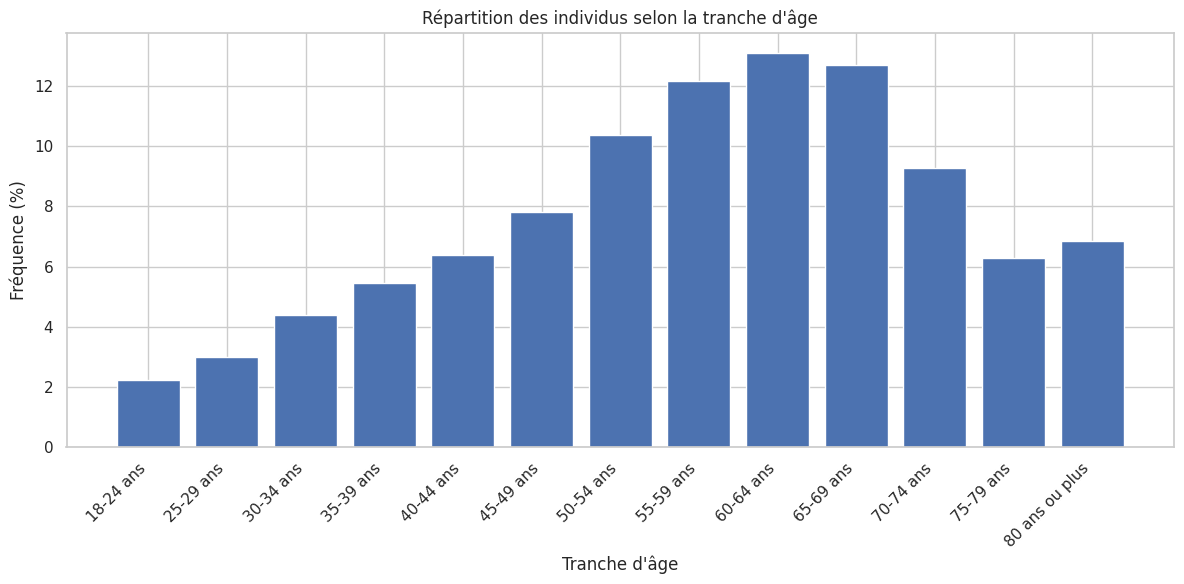

In [10]:
plt.figure(figsize=(12, 6))
plt.bar(age_frequences.index.astype(str), age_frequences["Fréquence (%)"])
plt.title("Répartition des individus selon la tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Fréquence (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 8.2. Variable `Age` — diagramme circulaire

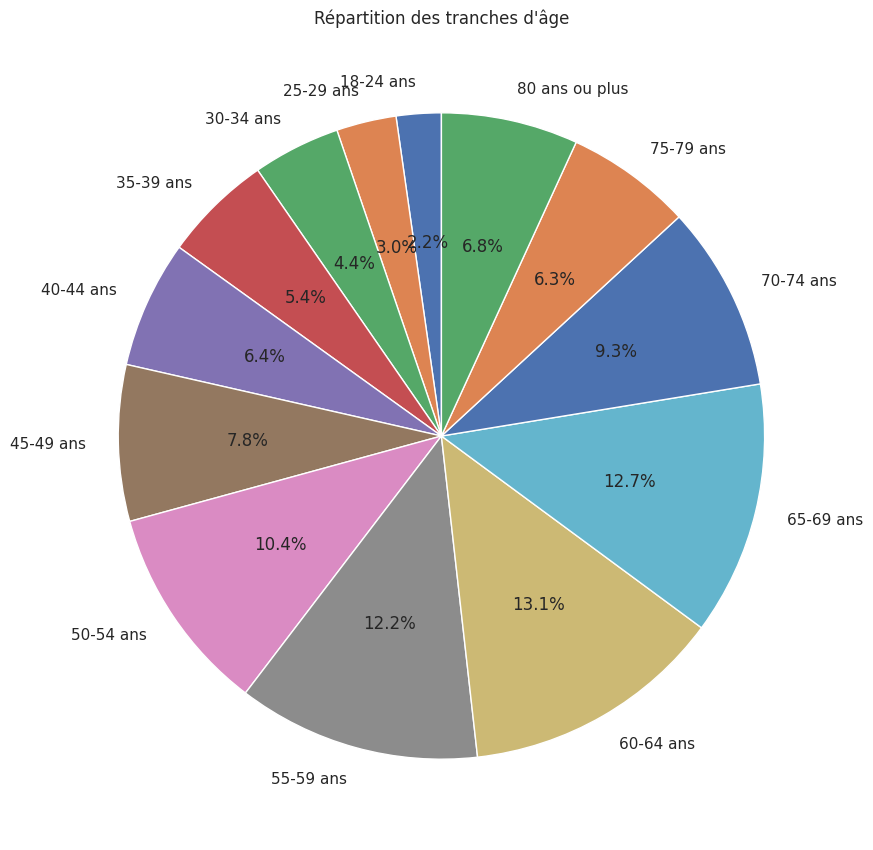

In [11]:
plt.figure(figsize=(9, 9))
plt.pie(
    age_frequences["Effectif"],
    labels=age_frequences.index.astype(str),
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Répartition des tranches d'âge")
plt.tight_layout()
plt.show()

### 8.3. Variable `MentHlth` — histogramme

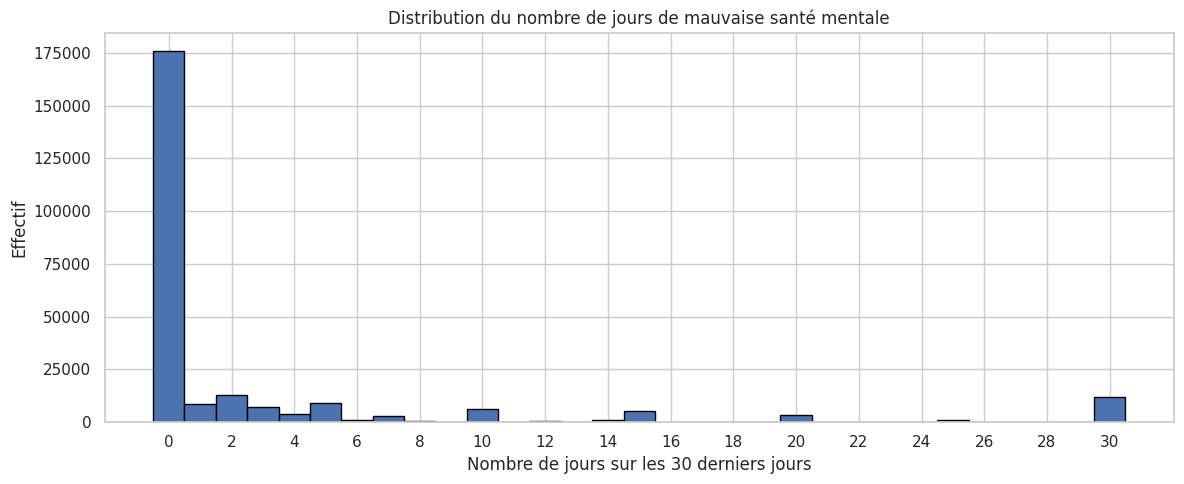

In [12]:
plt.figure(figsize=(12, 5))
plt.hist(df["MentHlth"], bins=np.arange(-0.5, 31.5, 1), edgecolor="black")
plt.title("Distribution du nombre de jours de mauvaise santé mentale")
plt.xlabel("Nombre de jours sur les 30 derniers jours")
plt.ylabel("Effectif")
plt.xticks(range(0, 31, 2))
plt.tight_layout()
plt.show()

### 8.4. Variable `MentHlth` — diagramme en barres des fréquences

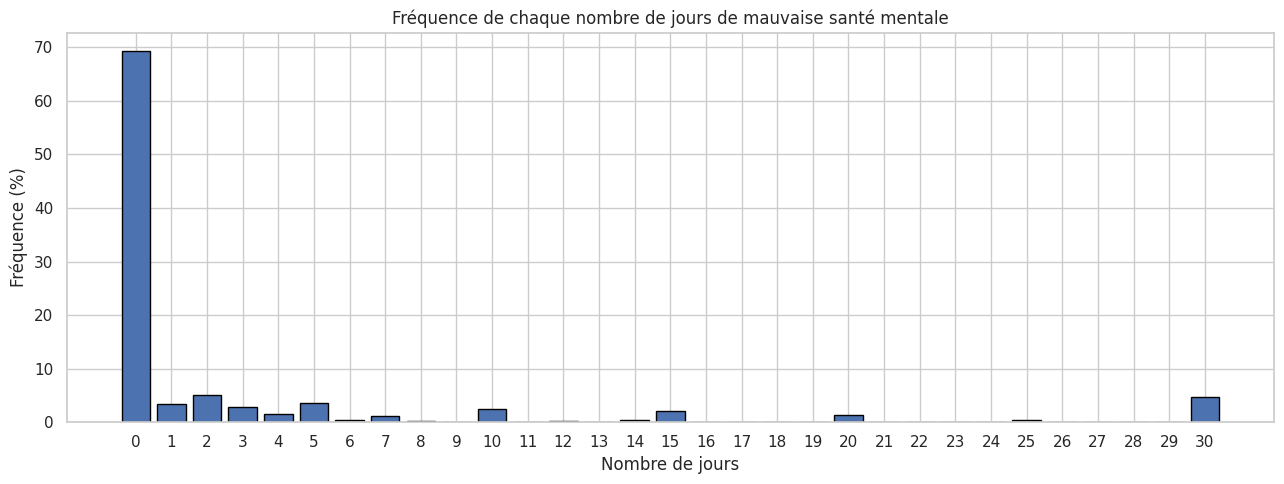

In [13]:
plt.figure(figsize=(13, 5))
plt.bar(
    menthlth_frequences.index,
    menthlth_frequences["Fréquence (%)"],
    edgecolor="black"
)
plt.title("Fréquence de chaque nombre de jours de mauvaise santé mentale")
plt.xlabel("Nombre de jours")
plt.ylabel("Fréquence (%)")
plt.xticks(range(0, 31))
plt.tight_layout()
plt.show()

### 8.5. Variable `MentHlth` — boîte à moustaches (boxplot)

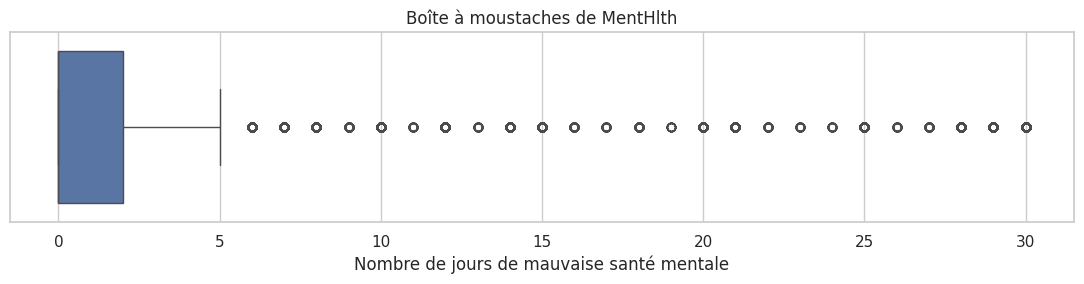

In [14]:
plt.figure(figsize=(11, 3))
sns.boxplot(x=df["MentHlth"])
plt.title("Boîte à moustaches de MentHlth")
plt.xlabel("Nombre de jours de mauvaise santé mentale")
plt.tight_layout()
plt.show()

### 8.6. Commentaire des graphiques

- Le diagramme en barres de `Age` confirme la plus forte représentation de la tranche 60-64 ans et la faible représentation de la tranche 18-24 ans.
- Le diagramme circulaire donne une vue des parts relatives, même si le diagramme en barres est plus facile à comparer lorsqu'il y a 13 catégories.
- L'histogramme et le diagramme en barres de `MentHlth` montrent une très forte concentration à 0 jour et une longue queue vers les valeurs élevées.
- Le boxplot met en évidence de nombreuses observations au-delà de la borne supérieure de l'IQR. Dans le contexte de cette variable, elles restent des réponses valides et sont conservées.

## 9. Analyse croisée : `Age` et `MentHlth`

En complément des analyses séparées, nous calculons le nombre moyen et médian de jours de mauvaise santé mentale pour chaque tranche d'âge. Cette comparaison permet d'explorer une éventuelle association descriptive entre les deux variables.

In [15]:
analyse_croisee = (
    df.groupby("Age_categorie", observed=False)["MentHlth"]
      .agg(Effectif="count", Moyenne="mean", Mediane="median")
      .reindex(age_order)
)
display(analyse_croisee.round(2))

,Effectif,Moyenne,Mediane
Age_categorie,,,
18-24 ans,5700,4.38,0.0
25-29 ans,7598,3.80,0.0
30-34 ans,11123,3.83,0.0
35-39 ans,13823,3.76,0.0
40-44 ans,16157,3.75,0.0
45-49 ans,19819,3.89,0.0
50-54 ans,26314,3.91,0.0
55-59 ans,30832,3.75,0.0
60-64 ans,33244,3.26,0.0


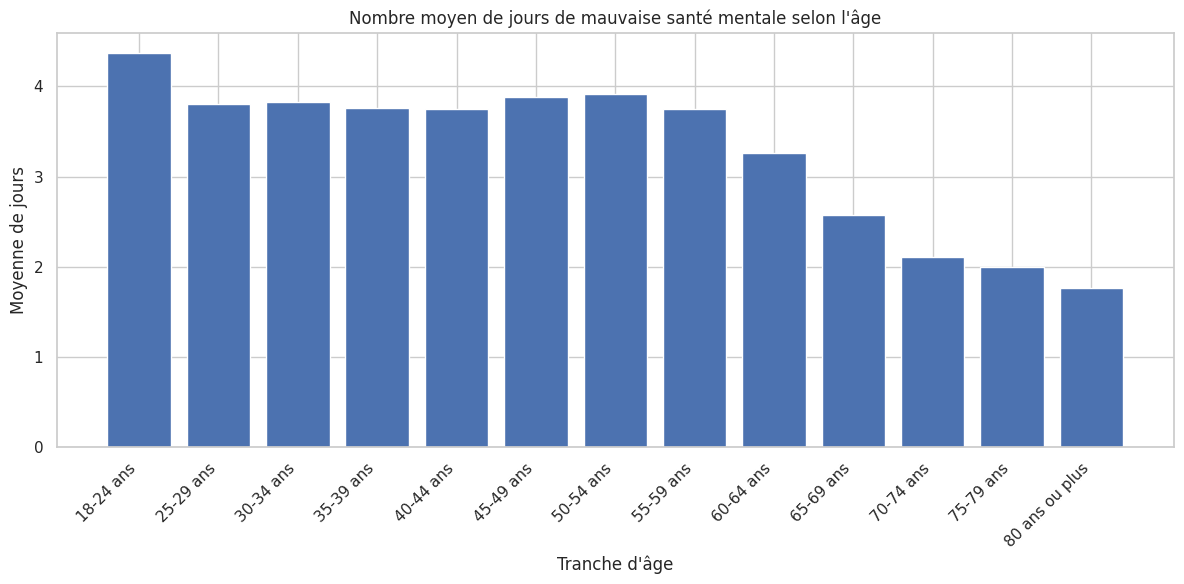

In [16]:
plt.figure(figsize=(12, 6))
plt.bar(analyse_croisee.index.astype(str), analyse_croisee["Moyenne"])
plt.title("Nombre moyen de jours de mauvaise santé mentale selon l'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Moyenne de jours")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 9.1. Interprétation de l'analyse croisée

La moyenne de `MentHlth` n'est pas identique d'une tranche d'âge à l'autre. Dans cet échantillon, elle est plus élevée chez les 18-24 ans (environ **4,38 jours**) et diminue globalement dans les tranches d'âge les plus élevées, jusqu'à environ **1,77 jour** chez les personnes de 80 ans ou plus.

Cette observation décrit une association dans le dataset. Elle ne permet pas de conclure que l'âge cause directement une amélioration ou une détérioration de la santé mentale. D'autres facteurs peuvent intervenir.

## 10. Conclusion générale

L'analyse descriptive de `Age` et `MentHlth` montre que l'échantillon est particulièrement représenté par les tranches d'âge autour de 55 à 69 ans, avec une modalité dominante de 60-64 ans. La variable `MentHlth` est fortement concentrée sur 0 jour : environ 69,25 % des répondants ne déclarent aucun jour de mauvaise santé mentale pendant les 30 derniers jours. Sa distribution présente une forte asymétrie à droite.

Aucune valeur manquante n'a été trouvée pour les deux variables. La méthode IQR ne signale aucune valeur atypique pour `Age`, mais identifie 14,27 % des observations de `MentHlth` comme atypiques au regard de ses bornes statistiques. Ces observations ont été conservées, car les valeurs situées entre 0 et 30 jours sont valides dans le contexte de l'étude. Enfin, les deux variables ont été normalisées par Min-Max, tout en conservant leurs colonnes originales.

L'analyse croisée suggère que la moyenne du nombre de jours de mauvaise santé mentale varie selon la tranche d'âge. Ce résultat reste descriptif et ne démontre pas une relation de causalité.

---

### Références méthodologiques et remarques

- Les statistiques descriptives sont calculées sur les observations disponibles dans le CSV fourni.
- L'écart-type et la variance de Pandas utilisent par défaut la correction d'échantillon (`ddof=1`).
- Le skewness et le kurtosis sont des indicateurs descriptifs ; ils sont à interpréter avec prudence pour une variable ordinale comme `Age`.
- Le seuil IQR repère des valeurs statistiquement éloignées, mais ne permet pas à lui seul de déterminer si une observation est une erreur.